<a href="https://colab.research.google.com/github/harshbagul33-blip/CIE_2_Activity_1_Multiple_Linear_Regression/blob/main/CIE_2_Activity_1_Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.api import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python Version:", sys.version.split()[0])
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

Python Version: 3.13.18
NumPy Version: 2.4.6
Pandas Version: 2.2.3


In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset: California Housing")
print("Source: https://scikit-learn.org/stable/datasets/real_world.html")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset: California Housing
Source: https://scikit-learn.org/stable/datasets/real_world.html
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nSummary Statistics:")
display(df.describe().T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010



Missing Values:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0



Duplicate Records: 0


In [4]:
target = "MedHouseVal"
feature_names = [col for col in df.columns if col != target]

X = df[feature_names].copy()
y = df[target].copy()

print("Input Features:", feature_names)
print("Target Variable:", target)

feature_descriptions = {
    "MedInc": "Median income in the block group",
    "HouseAge": "Median house age",
    "AveRooms": "Average number of rooms",
    "AveBedrms": "Average number of bedrooms",
    "Population": "Block group population",
    "AveOccup": "Average household occupancy",
    "Latitude": "Geographic latitude",
    "Longitude": "Geographic longitude",
    "MedHouseVal": "Median house value, in units of $100,000"
}
for name, description in feature_descriptions.items():
    print(f"{name}: {description}")

Input Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target Variable: MedHouseVal
MedInc: Median income in the block group
HouseAge: Median house age
AveRooms: Average number of rooms
AveBedrms: Average number of bedrooms
Population: Block group population
AveOccup: Average household occupancy
Latitude: Geographic latitude
Longitude: Geographic longitude
MedHouseVal: Median house value, in units of $100,000


In [5]:
print("Missing values before cleaning:", df.isnull().sum().sum())
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()
X = df[feature_names].copy()
y = df[target].copy()

print("Dataset shape after removing duplicate rows:", df.shape)
print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())

Missing values before cleaning: 0
Duplicate rows before cleaning: 0
Dataset shape after removing duplicate rows: (20640, 9)
Missing values after cleaning: 0
Duplicate rows after cleaning: 0


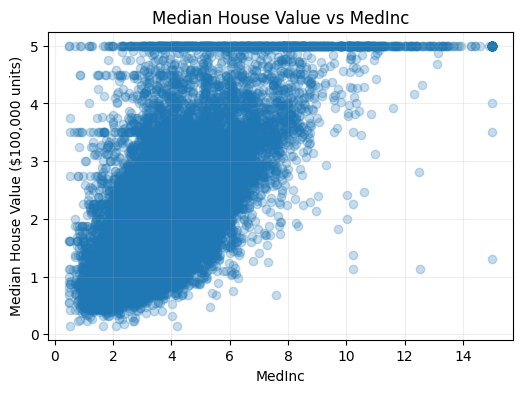

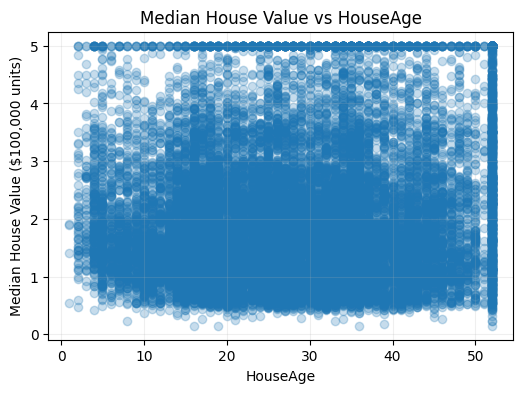

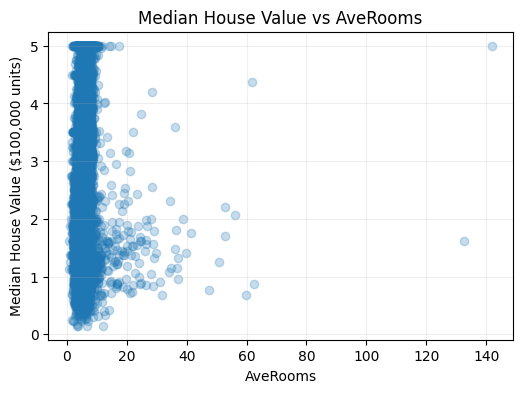

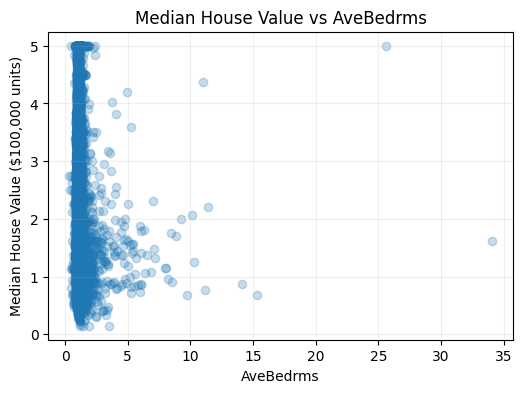

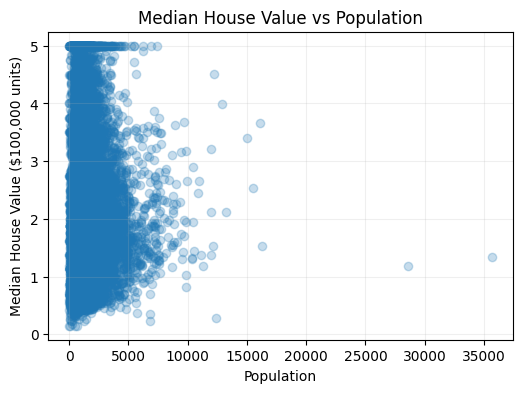

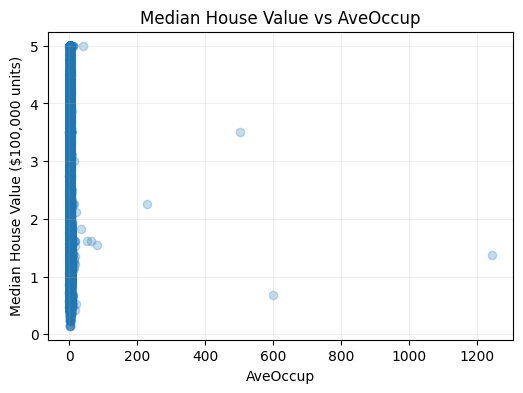

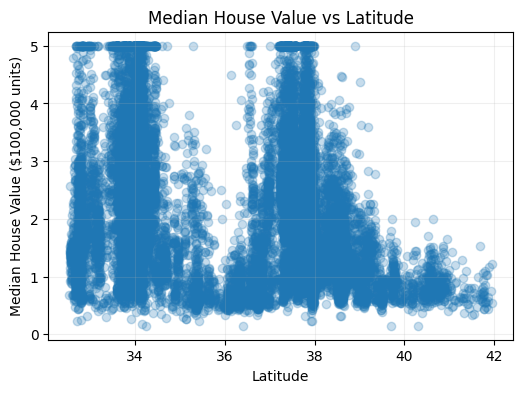

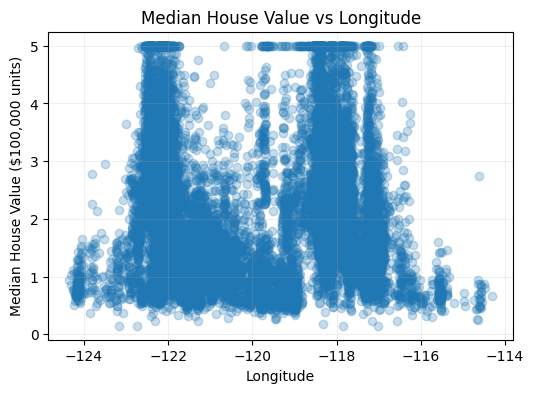

In [6]:
for feature in feature_names:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[feature], y, alpha=0.25)
    plt.title(f"Median House Value vs {feature}")
    plt.xlabel(feature)
    plt.ylabel("Median House Value ($100,000 units)")
    plt.grid(alpha=0.2)
    plt.show()

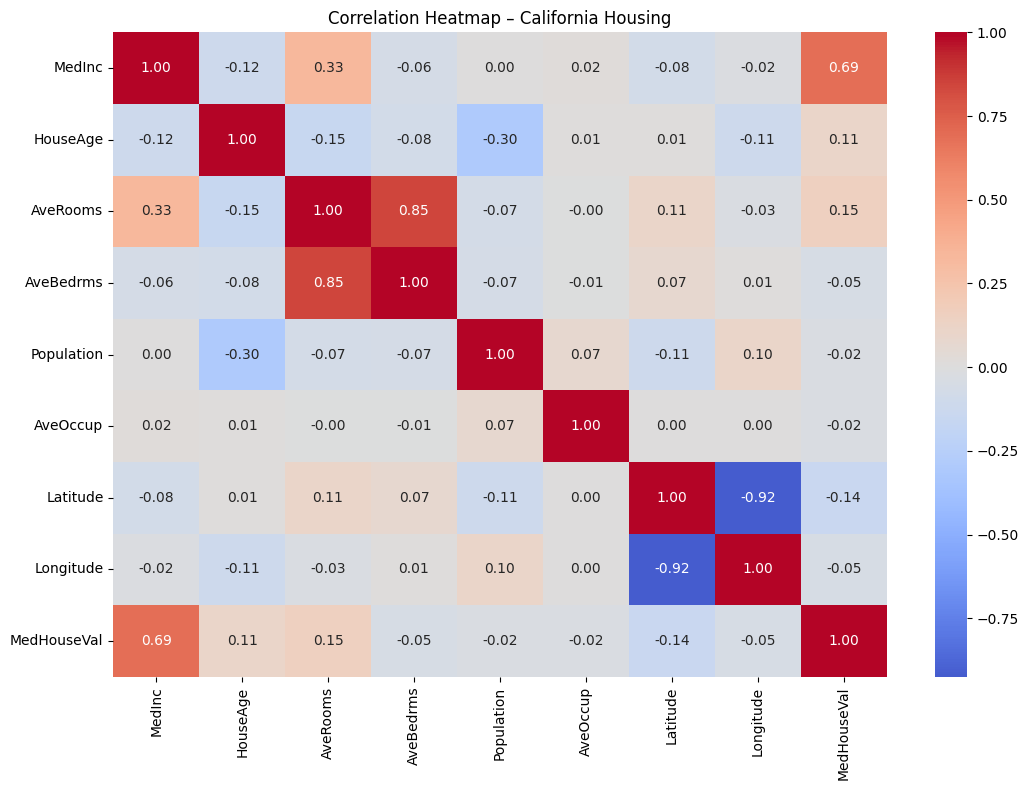

Correlation of each feature with the target:


,Correlation with MedHouseVal
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


Interpretation: The sign shows direction and the magnitude shows strength of linear association.
Correlation does not by itself prove causation.


In [7]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap – California Housing")
plt.tight_layout()
plt.show()

print("Correlation of each feature with the target:")
display(corr[target].drop(target).sort_values(ascending=False).to_frame("Correlation with MedHouseVal"))

print("Interpretation: The sign shows direction and the magnitude shows strength of linear association.")
print("Correlation does not by itself prove causation.")

In [8]:
manual_features = ["MedInc", "HouseAge"]
manual_sample = df[manual_features + [target]].iloc[[0, 100, 500, 1000, 5000, 10000]].copy()

X_manual = np.column_stack([
    np.ones(len(manual_sample)),
    manual_sample["MedInc"].to_numpy(),
    manual_sample["HouseAge"].to_numpy()
])
y_manual = manual_sample[target].to_numpy().reshape(-1, 1)

XTX = X_manual.T @ X_manual
XTy = X_manual.T @ y_manual
beta_manual = np.linalg.pinv(XTX) @ XTy

manual_predictions = X_manual @ beta_manual
manual_residuals = y_manual - manual_predictions

print("Selected observations:")
display(manual_sample)

print("Design matrix X:")
print(X_manual)

print("\nTarget vector y:")
print(y_manual)

print("\nX transpose X:")
print(XTX)

print("\nX transpose y:")
print(XTy)

print("\nManual coefficients [b0, b1, b2]:")
print(beta_manual.ravel())

print("\nFitted equation:")
print(
    f"y = {beta_manual[0, 0]:.6f} "
    f"+ ({beta_manual[1, 0]:.6f} × MedInc) "
    f"+ ({beta_manual[2, 0]:.6f} × HouseAge)"
)

manual_result = manual_sample.copy()
manual_result["Predicted"] = manual_predictions.ravel()
manual_result["Residual (actual - predicted)"] = manual_residuals.ravel()
display(manual_result)

Selected observations:


,MedInc,HouseAge,MedHouseVal
0,8.3252,41.0,4.526
100,2.4912,29.0,2.578
500,1.5817,52.0,1.536
1000,3.3841,29.0,1.844
5000,1.7159,49.0,0.950
10000,4.2031,13.0,2.096


Design matrix X:
[[ 1.      8.3252 41.    ]
 [ 1.      2.4912 29.    ]
 [ 1.      1.5817 52.    ]
 [ 1.      3.3841 29.    ]
 [ 1.      1.7159 49.    ]
 [ 1.      4.2031 13.    ]]

Target vector y:
[[4.526]
 [2.578]
 [1.536]
 [1.844]
 [0.95 ]
 [2.096]]

X transpose X:
[[6.00000000e+00 2.17012000e+01 2.13000000e+02]
 [2.17012000e+01 1.10079303e+02 7.32684700e+02]
 [2.13000000e+02 7.32684700e+02 8.63700000e+03]]

X transpose y:
[[ 13.53    ]
 [ 63.211743]
 [467.474   ]]

Manual coefficients [b0, b1, b2]:
[0.45820485 0.45678043 0.00407553]

Fitted equation:
y = 0.458205 + (0.456780 × MedInc) + (0.004076 × HouseAge)


,MedInc,HouseAge,MedHouseVal,Predicted,Residual (actual - predicted)
0,8.3252,41.0,4.526,4.428090,0.097910
100,2.4912,29.0,2.578,1.714327,0.863673
500,1.5817,52.0,1.536,1.392622,0.143378
1000,3.3841,29.0,1.844,2.122186,-0.278186
5000,1.7159,49.0,0.950,1.441695,-0.491695
10000,4.2031,13.0,2.096,2.431081,-0.335081


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 16512
Testing observations: 4128


In [10]:
mean_baseline_predictions = np.full(len(y_test), y_train.mean())

train_corr = X_train.join(y_train.rename(target)).corr(numeric_only=True)[target].drop(target)
best_feature = train_corr.abs().idxmax()

print("Selected single feature:", best_feature)

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)
single_predictions = single_model.predict(X_test[[best_feature]])

print("Single-feature intercept:", single_model.intercept_)
print("Single-feature coefficient:", single_model.coef_[0])

Selected single feature: MedInc
Single-feature intercept: 0.4445972916907879
Single-feature coefficient: 0.4193384939381271


In [11]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_predictions = multiple_model.predict(X_test)

print("Multiple-feature intercept:", multiple_model.intercept_)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": multiple_model.coef_
})
display(coefficient_table)

Multiple-feature intercept: -37.02327770606405


,Feature,Coefficient
0,MedInc,0.448675
1,HouseAge,0.009724
2,AveRooms,-0.123323
3,AveBedrms,0.783145
4,Population,-0.000002
5,AveOccup,-0.003526
6,Latitude,-0.419792
7,Longitude,-0.433708


In [12]:
library_manual_model = LinearRegression()
library_manual_model.fit(manual_sample[manual_features], manual_sample[target])

print("Manual coefficients [intercept, coefficients]:", beta_manual.ravel())
print("Library intercept:", library_manual_model.intercept_)
print("Library coefficients:", library_manual_model.coef_)
print("The manual and library results should be approximately equal, apart from numerical rounding.")

Manual coefficients [intercept, coefficients]: [0.45820485 0.45678043 0.00407553]
Library intercept: 0.45820485492654517
Library coefficients: [0.45678043 0.00407553]
The manual and library results should be approximately equal, apart from numerical rounding.


In [13]:
equation = f"MedHouseVal = {multiple_model.intercept_:.6f}"
for name, coef in zip(feature_names, multiple_model.coef_):
    equation += f" + ({coef:.6f} × {name})"

print("Multiple Linear Regression equation:")
print(equation)

print("\nInterpretation:")
print("Each coefficient estimates the change in the target for a one-unit increase in that feature,")
print("holding the other included features constant.")
print("The intercept is the predicted target when all features equal zero; this may not be meaningful")
print("if that combination is outside the realistic data range.")

Multiple Linear Regression equation:
MedHouseVal = -37.023278 + (0.448675 × MedInc) + (0.009724 × HouseAge) + (-0.123323 × AveRooms) + (0.783145 × AveBedrms) + (-0.000002 × Population) + (-0.003526 × AveOccup) + (-0.419792 × Latitude) + (-0.433708 × Longitude)

Interpretation:
Each coefficient estimates the change in the target for a one-unit increase in that feature,
holding the other included features constant.
The intercept is the predicted target when all features equal zero; this may not be meaningful
if that combination is outside the realistic data range.


In [14]:
x_std = X_train.std(ddof=0)
y_std = y_train.std(ddof=0)

standardized_coefficients = multiple_model.coef_ * x_std.to_numpy() / y_std

standardized_table = pd.DataFrame({
    "Feature": feature_names,
    "Raw Coefficient": multiple_model.coef_,
    "Standardized Coefficient": standardized_coefficients
}).sort_values("Standardized Coefficient", key=lambda s: s.abs(), ascending=False)

display(standardized_table)
print("Standardized coefficients help compare coefficient magnitudes across different feature units.")
print("They do not establish causation.")

,Feature,Raw Coefficient,Standardized Coefficient
6,Latitude,-0.419792,-0.775762
7,Longitude,-0.433708,-0.752334
0,MedInc,0.448675,0.738963
3,AveBedrms,0.783145,0.293429
2,AveRooms,-0.123323,-0.254638
1,HouseAge,0.009724,0.105991
5,AveOccup,-0.003526,-0.035313
4,Population,-0.000002,-0.001996


Standardized coefficients help compare coefficient magnitudes across different feature units.
They do not establish causation.


In [15]:
prediction_table = pd.DataFrame({
    "Actual": y_test.iloc[:15].to_numpy(),
    "Predicted": multiple_predictions[:15]
})
prediction_table["Residual (actual - predicted)"] = (
    prediction_table["Actual"] - prediction_table["Predicted"]
)
display(prediction_table)

,Actual,Predicted,Residual (actual - predicted)
0,0.47700,0.719123,-0.242123
1,0.45800,1.764017,-1.306017
2,5.00001,2.709659,2.290351
3,2.18600,2.838926,-0.652926
4,2.78000,2.604657,0.175343
5,1.58700,2.011754,-0.424754
6,1.98200,2.645500,-0.663500
7,1.57500,2.168755,-0.593755
8,3.40000,2.740746,0.659254
9,4.46600,3.915615,0.550385


In [16]:
def adjusted_r2(r2, n, p):
    if n <= p + 1:
        return np.nan
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def regression_metrics(actual, predicted, number_of_features):
    n = len(actual)
    r2 = r2_score(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2,
        "Adjusted R2": adjusted_r2(r2, n, number_of_features)
    }

results = pd.DataFrame({
    "Mean Baseline": regression_metrics(y_test, mean_baseline_predictions, 0),
    "Single Feature": regression_metrics(y_test, single_predictions, 1),
    "Multiple Features": regression_metrics(y_test, multiple_predictions, len(feature_names))
}).T

display(results.round(4))

print("MAE: Average absolute prediction error.")
print("MSE: Average squared prediction error.")
print("RMSE: Prediction error in the target's units.")
print("R2: Compares the model with a mean-based baseline; test R2 can be negative.")
print("Adjusted R2: Penalizes adding features that do not improve the model sufficiently.")

,MAE,MSE,RMSE,R2,Adjusted R2
Mean Baseline,0.9061,1.3107,1.1449,-0.0002,-0.0002
Single Feature,0.6299,0.7091,0.8421,0.4589,0.4587
Multiple Features,0.5332,0.5559,0.7456,0.5758,0.5750


MAE: Average absolute prediction error.
MSE: Average squared prediction error.
RMSE: Prediction error in the target's units.
R2: Compares the model with a mean-based baseline; test R2 can be negative.
Adjusted R2: Penalizes adding features that do not improve the model sufficiently.


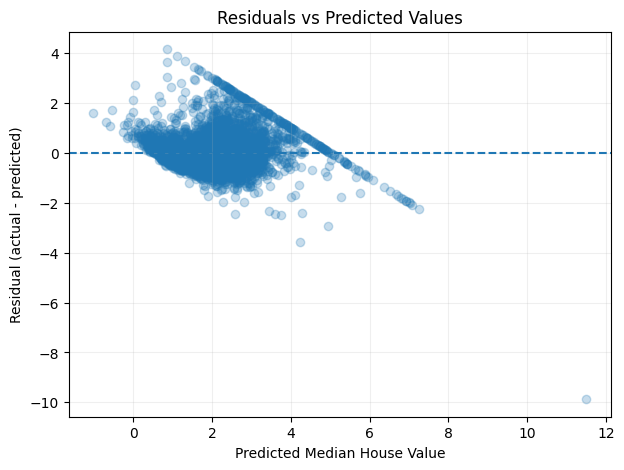

In [17]:
residuals = y_test.to_numpy() - multiple_predictions

plt.figure(figsize=(7, 5))
plt.scatter(multiple_predictions, residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Median House Value")
plt.ylabel("Residual (actual - predicted)")
plt.grid(alpha=0.2)
plt.show()

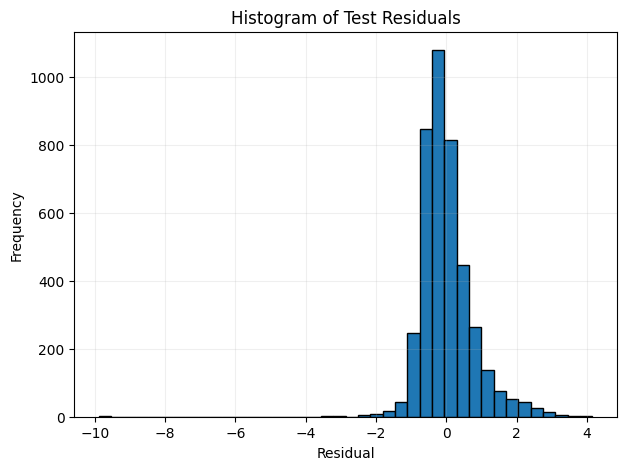

In [18]:
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=40, edgecolor="black")
plt.title("Histogram of Test Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.show()

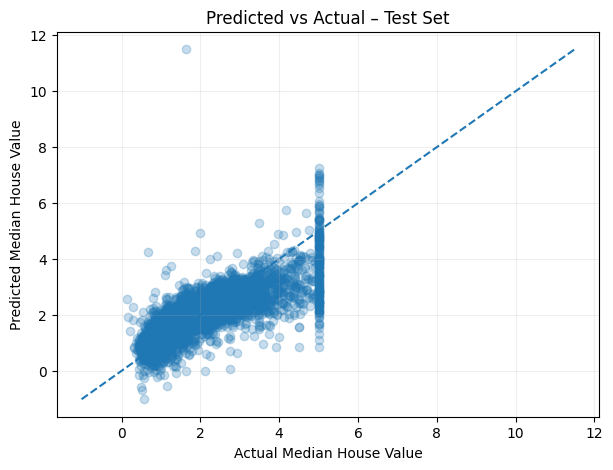

In [19]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, multiple_predictions, alpha=0.25)

low = min(y_test.min(), multiple_predictions.min())
high = max(y_test.max(), multiple_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")

plt.title("Predicted vs Actual – Test Set")
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.grid(alpha=0.2)
plt.show()

In [20]:
X_vif = add_constant(X_train)

vif_table = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.to_numpy(), i)
        for i in range(X_vif.shape[1])
    ]
})

vif_table = vif_table[vif_table["Feature"] != "const"]
display(vif_table.sort_values("VIF", ascending=False))

print("VIF values around 1 indicate low multicollinearity.")
print("Values above 5 can warrant investigation; values above 10 can indicate serious multicollinearity.")
print("Use the data context as well as VIF before deciding whether to remove or combine features.")

,Feature,VIF
7,Latitude,9.206134
8,Longitude,8.875984
3,AveRooms,7.917240
4,AveBedrms,6.609200
1,MedInc,2.539815
2,HouseAge,1.237337
5,Population,1.134824
6,AveOccup,1.009733


VIF values around 1 indicate low multicollinearity.
Values above 5 can warrant investigation; values above 10 can indicate serious multicollinearity.
Use the data context as well as VIF before deciding whether to remove or combine features.


In [21]:
print("1. Linearity: The relationship between predictors and the target should be approximately linear.")
print("2. Independence of errors: Errors should be independent of one another.")
print("3. Constant variance: Residuals should have approximately constant variance.")
print("4. Normality of errors: Residuals should be approximately normally distributed for conventional inference.")
print("5. No severe multicollinearity: Predictors should not have severe linear dependence.")

print("\nUse the scatter plots, residual plots, histogram and VIF results to assess these assumptions.")
print("These checks do not prove that every assumption is satisfied.")

1. Linearity: The relationship between predictors and the target should be approximately linear.
2. Independence of errors: Errors should be independent of one another.
3. Constant variance: Residuals should have approximately constant variance.
4. Normality of errors: Residuals should be approximately normally distributed for conventional inference.
5. No severe multicollinearity: Predictors should not have severe linear dependence.

Use the scatter plots, residual plots, histogram and VIF results to assess these assumptions.
These checks do not prove that every assumption is satisfied.


In [22]:
new_house = pd.DataFrame([{
    feature: X_train[feature].median()
    for feature in feature_names
}])

new_prediction = multiple_model.predict(new_house)[0]

print("New example:")
display(new_house)

print(f"Predicted median house value: {new_prediction:.4f} units of $100,000")
print(f"Approximate value in dollars: ${new_prediction * 100000:,.2f}")

New example:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.5458,29.0,5.235874,1.049286,1167.0,2.81724,34.26,-118.51


Predicted median house value: 2.0300 units of $100,000
Approximate value in dollars: $203,002.36
